### EN3160 Assignment 3 on on Neural Networks

#### Index Number: 230724E
#### Name: Wijesekara WAGS

---

##### Github Link:  https://github.com/SathsaraGeeth/_vision_a03_.git

### 1. Modifying the Single-Layer Neural Network

(a) A hidden layer with 100 neurons and sigmoid activation was added between the input and output layers. The forward propagation and manual backpropagation were modified accordingly.

(b) The original mean squared error loss was replaced with cross-entropy loss for multiclass classification.

$$
L=-\frac{1}{N}\sum_{i=1}^{N}\log(p_{i,y_i})
$$

The gradients were calculated manually using the chain rule.

(c) The network was trained for 10 epochs using a learning rate of 0.01.

- Training accuracy: 37.12%
- Test accuracy: 37.30%
- Initial loss: 2.2078
- Final loss: 1.7925

/home/geeth/miniconda3/envs/yolov13/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Epoch 1/10, Loss: 2.207803058385849
Epoch 2/10, Loss: 2.021340085864067
Epoch 3/10, Loss: 1.943696902513504
Epoch 4/10, Loss: 1.9016104465723038
Epoch 5/10, Loss: 1.8719940112829208
Epoch 6/10, Loss: 1.8488756144046783
Epoch 7/10, Loss: 1.8300811433792115
Epoch 8/10, Loss: 1.8150055284500122
Epoch 9/10, Loss: 1.8027854161262513
Epoch 10/10, Loss: 1.7925096703767776


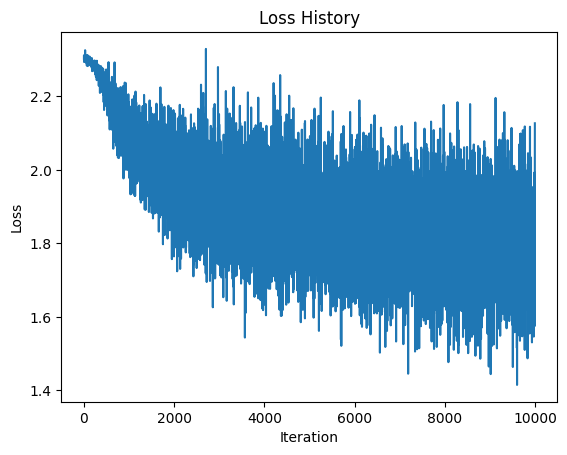

Training accuracy: 37.12%
Test accuracy: 37.30%


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100 # Hidden layer with 100 neurons
K = 10  # Output size (number of classes in CIFAR-10)
std = 0.01 # 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * std  # Input to hidder layer
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std # Hidden layer to output layer
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 0.01 # 2e-6  # Learning rate
lr_decay = 0.9  # Learning rate decay
reg = 0  # Regularization
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot

        # Forward pass
        z1 = x_train.mm(w1) + b1
        a1 = torch.sigmoid(z1)
        y_pred = a1.mm(w2) + b2  # Output layer activation

        # Loss calculation (Cross Entropy with regularization)
        loss = nn.functional.cross_entropy(y_pred, labels) + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1) - y_train_onehot
        dy_pred /= Ntr

        dw2 = a1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)

        da1 = dy_pred.mm(w2.t())
        dz1 = da1 * a1 * (1 - a1)
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a1 = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = a1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        a1 = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = a1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

## 2. Implementing LeNet-5 and a Small 3-Layer CNN Using PyTorch

LeNet-5 and SmallCNN3 were trained on MNIST for 10 epochs under the same conditions. The training and test accuracy and loss were recorded for each epoch, and confusion matrices were generated to evaluate classification performance.

| Metric | LeNet-5 | SmallCNN3 |
|---|---|---|
| Training Accuracy | 98.53% | 98.51% |
| Test Accuracy | 98.25% | 97.65% |
| Training Loss | 0.0524 | 0.0468 |
| Test Loss | 0.0615 | 0.0698 |
| Training Time | 1m 0.9s | 2m 25.3s |

Both models achieved high classification accuracy with relatively small differences between training and test performance. LeNet-5 performed slightly better in this experiment despite its simpler architecture.

In [9]:
# LeNet-5 Architecture
# --------------------
#
# Input:    1 x 32 x 32
# Conv1:    6 x 28 x 28   (5x5 convolution)
# SubSamp1: 6 x 14 x 14   (2x2 pooling)
# Conv2:    16 x 10 x 10  (5x5 convolution)
# SubSamp2: 16 x 5 x 5    (2x2 pooling)
# Flatten:  400
# FC1:      120 neurons   (Tanh)
# FC2:      84 neurons    (Tanh)
# Output:   10 neurons    (Gaussian RBF)

class SubsamplingLayer(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.weight = nn.Parameter(torch.ones(channels))
        self.bias = nn.Parameter(torch.zeros(channels))

    def forward(self, x):
        x = self.pool(x)
        return torch.tanh(x * self.weight.view(1, -1, 1, 1) + self.bias.view(1, -1, 1, 1))

class GaussianLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer("prototypes", torch.randn(10, 84))

    def forward(self, x):
        return ((x.unsqueeze(1) - self.prototypes) ** 2).sum(dim=2)

class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.subs1 = SubsamplingLayer(6)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.subs2 = SubsamplingLayer(16)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.output = GaussianLayer()

    def forward(self, x):
        x = torch.tanh(self.conv1(x))
        x = self.subs1(x)
        x = torch.tanh(self.conv2(x))
        x = self.subs2(x)
        x = torch.flatten(x, 1)
        x = torch.tanh(self.fc1(x))
        x = torch.tanh(self.fc2(x))
        x = self.output(x)
        return -x

In [19]:
# SmallCNN3 Architecture
# ----------------------
#
# Input:    1 x 32 x 32
# Conv1:    32 x 32 x 32   (3x3 convolution, BatchNorm, ReLU)
# MaxPool1: 32 x 16 x 16   (2x2 pooling)
# Conv2:    64 x 16 x 16   (3x3 convolution, BatchNorm, ReLU)
# MaxPool2: 64 x 8 x 8     (2x2 pooling)
# Conv3:    128 x 8 x 8    (3x3 convolution, BatchNorm, ReLU)
# AvgPool:  128 x 1 x 1    (Global Average Pooling)
# Flatten:  128
# Dropout:  0.5
# FC:       10 neurons

class SmallCNN3(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool(torch.relu(self.bn2(self.conv2(x))))
        x = torch.relu(self.bn3(self.conv3(x)))
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

In [17]:
# Load the dataset
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

batch_size = 50

trainset = torchvision.datasets.MNIST(
    root='./data', train=True, download=True, transform=transform
)

testset = torchvision.datasets.MNIST(
    root='./data', train=False, download=True, transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2
)

testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Train and Evaluation
def evaluate(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * labels.size(0)
            predicted = torch.argmax(outputs, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return running_loss / total, 100 * correct / total


def train_model(model, epochs=10):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {
        "train_loss": [],
        "test_loss": [],
        "train_acc": [],
        "test_acc": []
    }

    for epoch in range(epochs):
        model.train()

        for inputs, labels in trainloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, trainloader, criterion)
        test_loss, test_acc = evaluate(model, testloader, criterion)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Train Loss: {train_loss:.4f}, "
            f"Test Loss: {test_loss:.4f}, "
            f"Train Acc: {train_acc:.2f}%, "
            f"Test Acc: {test_acc:.2f}%"
        )

    return model, history

In [13]:
# Plot
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Train")
    plt.plot(epochs, history["test_loss"], label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Train")
    plt.plot(epochs, history["test_acc"], label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [ ]:
# Confusion Matrix
def plot_confusion_matrix(model, loader, title):
    model.eval()

    cm = torch.zeros(10, 10, dtype=torch.int64)

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            predicted = torch.argmax(outputs, dim=1).cpu()

            for actual, pred in zip(labels, predicted):
                cm[actual, pred] += 1

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()

    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"{title} Confusion Matrix")

    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j].item(), ha="center", va="center", fontsize=8)

    plt.tight_layout()
    plt.show()

Epoch 1/10, Train Loss: 0.2276, Test Loss: 0.2045, Train Acc: 93.58%, Test Acc: 94.08%
Epoch 2/10, Train Loss: 0.1436, Test Loss: 0.1402, Train Acc: 95.55%, Test Acc: 95.64%
Epoch 3/10, Train Loss: 0.0982, Test Loss: 0.0987, Train Acc: 96.97%, Test Acc: 96.84%
Epoch 4/10, Train Loss: 0.0962, Test Loss: 0.0908, Train Acc: 97.09%, Test Acc: 97.18%
Epoch 5/10, Train Loss: 0.0790, Test Loss: 0.0821, Train Acc: 97.67%, Test Acc: 97.59%
Epoch 6/10, Train Loss: 0.0546, Test Loss: 0.0567, Train Acc: 98.38%, Test Acc: 98.27%
Epoch 7/10, Train Loss: 0.0527, Test Loss: 0.0592, Train Acc: 98.39%, Test Acc: 98.26%
Epoch 8/10, Train Loss: 0.0518, Test Loss: 0.0639, Train Acc: 98.47%, Test Acc: 98.29%
Epoch 9/10, Train Loss: 0.0419, Test Loss: 0.0473, Train Acc: 98.75%, Test Acc: 98.57%
Epoch 10/10, Train Loss: 0.0524, Test Loss: 0.0615, Train Acc: 98.53%, Test Acc: 98.25%


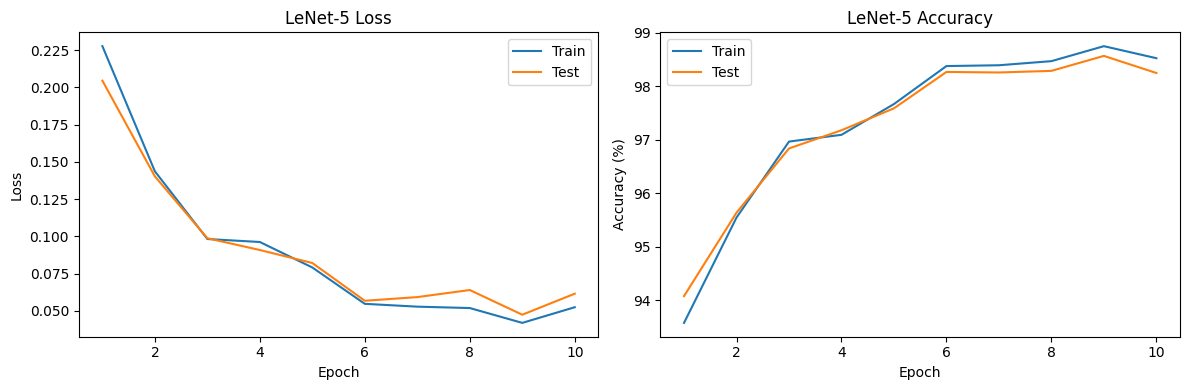

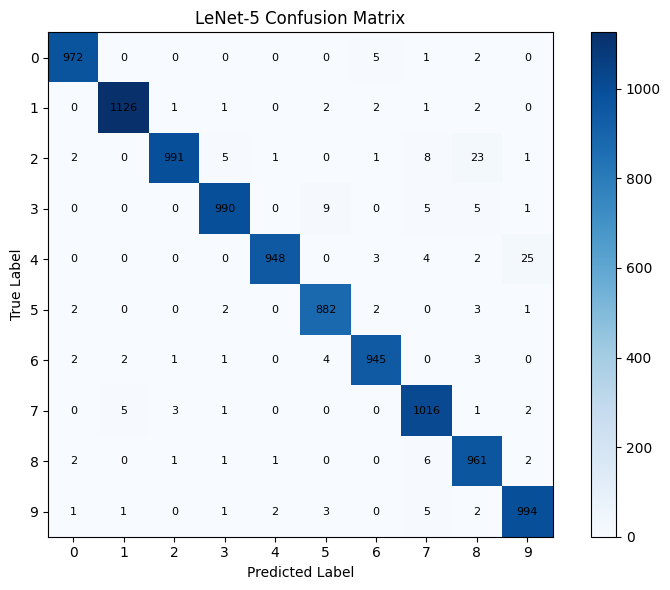

LeNet-5 Training Accuracy: 98.53%
LeNet-5 Test Accuracy: 98.25%


In [16]:
# Train LeNet-5
lenet = LeNet5()
lenet, lenet_history = train_model(lenet, epochs=10)
plot_history(lenet_history, "LeNet-5")
plot_confusion_matrix(lenet, testloader, "LeNet-5")
print(f"LeNet-5 Training Accuracy: {lenet_history['train_acc'][-1]:.2f}%")
print(f"LeNet-5 Test Accuracy: {lenet_history['test_acc'][-1]:.2f}%")

Epoch 1/10, Train Loss: 0.1065, Test Loss: 0.1071, Train Acc: 97.22%, Test Acc: 97.04%
Epoch 2/10, Train Loss: 0.0831, Test Loss: 0.0871, Train Acc: 97.53%, Test Acc: 97.41%
Epoch 3/10, Train Loss: 0.0959, Test Loss: 0.1055, Train Acc: 97.02%, Test Acc: 96.79%
Epoch 4/10, Train Loss: 0.0488, Test Loss: 0.0576, Train Acc: 98.55%, Test Acc: 98.26%
Epoch 5/10, Train Loss: 0.0504, Test Loss: 0.0559, Train Acc: 98.52%, Test Acc: 98.20%
Epoch 6/10, Train Loss: 0.0374, Test Loss: 0.0485, Train Acc: 98.89%, Test Acc: 98.60%
Epoch 7/10, Train Loss: 0.0322, Test Loss: 0.0500, Train Acc: 98.99%, Test Acc: 98.49%
Epoch 8/10, Train Loss: 0.0446, Test Loss: 0.0566, Train Acc: 98.56%, Test Acc: 98.11%
Epoch 9/10, Train Loss: 0.0229, Test Loss: 0.0389, Train Acc: 99.36%, Test Acc: 98.77%
Epoch 10/10, Train Loss: 0.0468, Test Loss: 0.0698, Train Acc: 98.51%, Test Acc: 97.65%


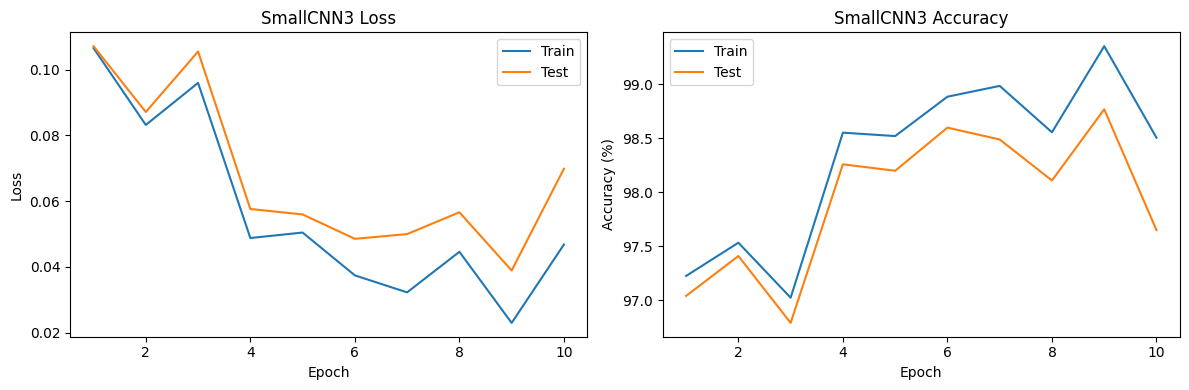

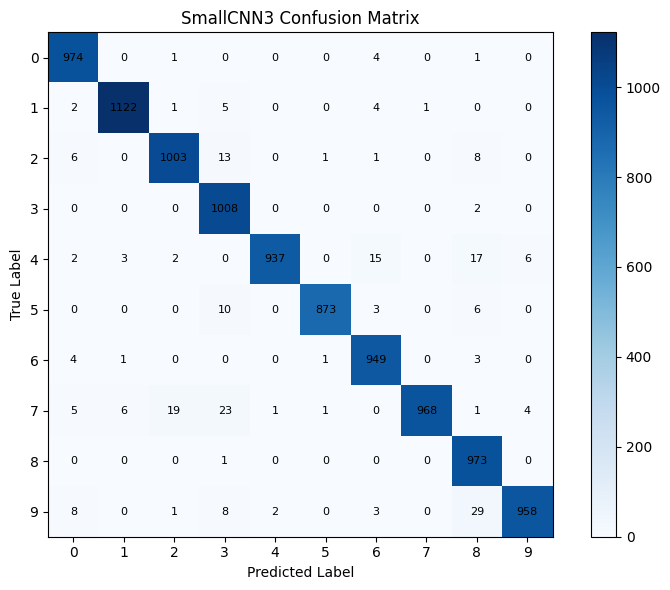

SmallCNN3 Training Accuracy: 98.51%
SmallCNN3 Test Accuracy: 97.65%


In [20]:
# Train SmallCNN3
smallcnn = SmallCNN3()
smallcnn, smallcnn_history = train_model(smallcnn, epochs=10)
plot_history(smallcnn_history, "SmallCNN3")
plot_confusion_matrix(smallcnn, testloader, "SmallCNN3")
print(f"SmallCNN3 Training Accuracy: {smallcnn_history['train_acc'][-1]:.2f}%")
print(f"SmallCNN3 Test Accuracy: {smallcnn_history['test_acc'][-1]:.2f}%")

## 3. Transfer Learning Using Pre-trained ResNet-18
